# Phân cụm và đánh giá tương đồng văn bản

Giải cả 3 câu trong một notebook. K chọn ở câu a được dùng trực tiếp ở câu b.

Chuỗi biến: `names`, `raw` → `docs` → `X` → `labels` / top 5 cặp

**Khi đổi đề:** chỉ sửa ô cấu hình, chạy lại toàn bộ, rồi viết lại phần kết luận ở câu a theo số liệu mới.

In [1]:
# ===== CẤU HÌNH =====
DATA_DIR = "Data"
STOPWORDS_FILE = "vietnamese-stopwords.txt"
DA_TIEN_XU_LY = False       # True nếu đề cho dữ liệu đã tách từ, làm sạch sẵn

DAC_TRUNG = "tfidf"         # "tfidf" hoặc "bow"
NGRAM = (1, 1)              # (1, 2) nếu đề yêu cầu thêm bigram
MAX_DF, MIN_DF = 0.5, 2

K_MIN, K_MAX = 2, 10
K_CHON = None               # None: lấy K theo Silhouette; đặt số để tự chọn, ví dụ K_CHON = 5

HIEN_THI = "ten_file"       # "ten_file" hoặc "d" (in d0, d1, ... như mẫu đề)
DO_DO = "cosine"            # "cosine", "jaccard" hoặc "euclidean"
RANDOM_STATE = 42

In [2]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import underthesea
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.metrics.pairwise import cosine_similarity, euclidean_distances

## Bước 1. Đọc dữ liệu

In [3]:
def doc_file(path):
    for encoding in ("utf-8-sig", "utf-16", "cp1258"):
        try:
            with open(path, encoding=encoding) as f:
                return f.read()
        except (UnicodeError, UnicodeDecodeError):
            continue
    raise ValueError(f"Không đọc được file: {path}")

def natural_key(name):
    return [int(p) if p.isdigit() else p for p in re.split(r"(\d+)", name)]

names = sorted([f for f in os.listdir(DATA_DIR) if f.endswith(".txt")], key=natural_key)
raw = [doc_file(os.path.join(DATA_DIR, f)) for f in names]

print("Số file:", len(names))
print("Ví dụ:", names[0], "->", raw[0].strip()[:150])

Số file: 475
Ví dụ: AN_TN_ (878).txt -> Đó là chủ đề liveshow Sắc màu âm nhạc tháng 4, sẽ diễn ra vào lúc 20 giờ ngày 10.4.2006 tại Câu lạc bộ Nguyễn Du (TP.HCM). Tham gia chương trình lần n


## Bước 2. Tiền xử lý

Xem dòng ví dụ ở trên trước. Nếu dữ liệu đã xử lý sẵn thì đặt `DA_TIEN_XU_LY = True`.

In [4]:
with open(STOPWORDS_FILE, encoding="utf-8") as f:
    stopwords = set(w.strip().lower().replace(" ", "_") for w in f if w.strip())

def tien_xu_ly(doc):
    text = underthesea.text_normalize(doc).lower()      # Chuẩn hóa dấu, chữ thường
    text = re.sub(r"http\S+|www\S+", " ", text)         # Xóa URL
    text = re.sub(r"\S*@\S*", " ", text)                # Xóa email
    text = underthesea.word_tokenize(text, format="text")   # Tách từ
    text = re.sub(r"[^\w\s]", " ", text)                # Xóa dấu câu, giữ dấu _ của từ ghép
    text = re.sub(r"\S*\d\S*", " ", text)               # Xóa số và từ dính số
    return " ".join(w for w in text.split() if w not in stopwords)

docs = [d.strip() if DA_TIEN_XU_LY else tien_xu_ly(d) for d in raw]

# Bỏ văn bản rỗng, giữ names và docs luôn cùng thứ tự
giu_lai = [i for i, d in enumerate(docs) if d]
names = [names[i] for i in giu_lai]
docs = [docs[i] for i in giu_lai]

print("Số văn bản sau tiền xử lý:", len(docs))
print("Ví dụ:", docs[0][:150])

Số văn bản sau tiền xử lý: 475
Ví dụ: chủ_đề liveshow sắc_màu âm_nhạc diễn câu_lạc_bộ nguyễn_du tp hcm tham_gia chương_trình ca_sĩ hồ ngọc_hà phương lưu hương_giang vương_dung hoàng lê_vy 


## Bước 3. Trích xuất đặc trưng

In [5]:
Vectorizer = TfidfVectorizer if DAC_TRUNG == "tfidf" else CountVectorizer
vectorizer = Vectorizer(max_df=MAX_DF, min_df=MIN_DF, ngram_range=NGRAM)
X = vectorizer.fit_transform(docs)
print("Kích thước X (số văn bản, số từ):", X.shape)

Kích thước X (số văn bản, số từ): (475, 4831)


## Câu a. Xác định K bằng Elbow và Silhouette

 K     WCSS  WCSS giảm  Silhouette
 2 448.1572        NaN      0.0183
 3 439.3223     8.8350      0.0269
 4 431.0578     8.2645      0.0322
 5 424.9478     6.1099      0.0370
 6 420.4719     4.4759      0.0351
 7 416.8529     3.6190      0.0314
 8 415.5691     1.2838      0.0314
 9 412.3351     3.2340      0.0302
10 409.6181     2.7170      0.0279


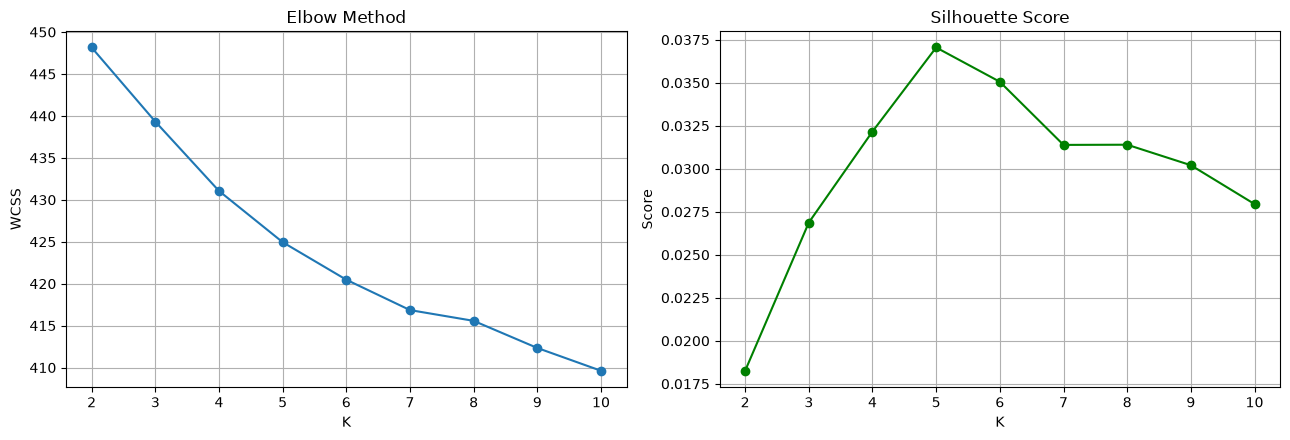

In [6]:
K_values = list(range(K_MIN, K_MAX + 1))
wcss, silhouette = [], []

for k in K_values:
    km = KMeans(n_clusters=k, init="k-means++", max_iter=300, n_init=10, random_state=RANDOM_STATE)
    km.fit(X)
    wcss.append(km.inertia_)
    silhouette.append(silhouette_score(X, km.labels_))

bang_k = pd.DataFrame({"K": K_values, "WCSS": wcss, "WCSS giảm": -pd.Series(wcss).diff(), "Silhouette": silhouette})
print(bang_k.round(4).to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(K_values, wcss, marker="o")
ax[0].set(title="Elbow Method", xlabel="K", ylabel="WCSS")
ax[1].plot(K_values, silhouette, marker="o", color="g")
ax[1].set(title="Silhouette Score", xlabel="K", ylabel="Score")
for a in ax:
    a.grid(True)
plt.tight_layout()
plt.show()

In [7]:
# Silhouette chọn được bằng code. Elbow phải đọc trên biểu đồ, xem cột "WCSS giảm".
K_silhouette = K_values[int(np.argmax(silhouette))]
K = K_CHON if K_CHON is not None else K_silhouette
print("K có Silhouette cao nhất:", K_silhouette)
print("K dùng cho câu b:", K)

K có Silhouette cao nhất: 5
K dùng cho câu b: 5


**Kết luận:**

- **Elbow:** WCSS giảm đều, không có khuỷu rõ. Mức giảm chậm dần từ 8.84 (K=3) xuống 4.48 (K=6), nên chỉ gợi ý vùng K khoảng 5–7.
- **Silhouette:** cao nhất tại K=5 (0.0370).
- **Chọn K = 5.** Điểm Silhouette thấp nên các cụm không tách biệt mạnh; K=5 chỉ là giá trị tốt nhất trong khoảng K=2–10 đã thử.

## Câu b. Phân cụm K-Means

In [8]:
km = KMeans(n_clusters=K, init="k-means++", max_iter=300, n_init=10, random_state=RANDOM_STATE)
labels = km.fit_predict(X)

def ten(i):
    return f"d{i}" if HIEN_THI == "d" else names[i]

print(f"Số cụm: {K}")
print("Phân cụm:")
for c in range(K):
    print(f"Cụm {c + 1}: " + ", ".join(ten(i) for i in np.where(labels == c)[0]))

ket_qua = pd.DataFrame({"ma": [f"d{i}" for i in range(len(names))], "file": names, "cluster": labels + 1})
ket_qua.to_csv("ket_qua_phan_cum.csv", index=False, encoding="utf-8-sig")
print("\nSố văn bản mỗi cụm:")
print(ket_qua["cluster"].value_counts().sort_index().to_string())

Số cụm: 5
Phân cụm:
Cụm 1: AN_TN_ (878).txt, AN_TN_ (879).txt, AN_TN_ (880).txt, AN_TN_ (881).txt, AN_TN_ (882).txt, AN_TN_ (883).txt, AN_TN_ (884).txt, AN_TN_ (885).txt, AN_TN_ (886).txt, AN_TN_ (887).txt, AN_TN_ (888).txt, AN_TN_ (889).txt, AN_TN_ (890).txt, AN_TN_ (891).txt, AN_TN_ (892).txt, AN_TN_ (893).txt, AN_TT_ (894).txt, AN_TT_ (895).txt, AN_TT_ (896).txt, AN_TT_ (897).txt, AN_TT_ (898).txt, AN_TT_ (899).txt, AN_TT_ (900).txt, AN_VNE_ (1).txt, AN_VNE_ (2).txt, AN_VNE_ (3).txt, AN_VNE_ (4).txt, AN_VNE_ (5).txt, AN_VNE_ (6).txt, AN_VNE_ (7).txt, AN_VNE_ (8).txt, AN_VNE_ (9).txt, AN_VNE_ (10).txt, AN_VNE_ (11).txt, AN_VNE_ (12).txt, AN_VNE_ (13).txt, AN_VNE_ (14).txt, AN_VNE_ (15).txt, AN_VNE_ (16).txt, AN_VNE_ (17).txt, AN_VNE_ (18).txt, AN_VNE_ (19).txt, AN_VNE_ (20).txt, AN_VNE_ (21).txt, AN_VNE_ (22).txt, AN_VNE_ (23).txt, AN_VNE_ (25).txt, AN_VNE_ (26).txt, AN_VNE_ (27).txt, AN_VNE_ (28).txt, AN_VNE_ (29).txt, AN_VNE_ (30).txt, AN_VNE_ (31).txt, AN_VNE_ (32).txt, AN_VNE_ (3

### Tự kiểm tra (đề không yêu cầu)

Chỉ dùng được khi tên file có chứa chủ đề, ở đây là phần đứng trước dấu `_` đầu tiên.

In [9]:
chu_de = [n.split("_")[0] for n in names]
print(pd.crosstab(pd.Series(labels + 1, name="Cụm"), pd.Series(chu_de, name="Chủ đề")))

Chủ đề  AN  BDS  DL  GDu  TT
Cụm                         
1       93    0   0    2  20
2        1    4  95    2   0
3        0    0   0   91   1
4        1    0   0    0  74
5        0   91   0    0   0


## Câu c. Top 5 cặp tương đồng nhất

Cosine và Jaccard: càng **lớn** càng giống. Euclidean: càng **nhỏ** càng giống.

In [10]:
def ma_tran_jaccard(docs):
    tap_tu = [set(d.split()) for d in docs]
    M = np.zeros((len(docs), len(docs)))
    for i in range(len(docs)):
        for j in range(i + 1, len(docs)):
            hop = tap_tu[i] | tap_tu[j]
            M[i, j] = len(tap_tu[i] & tap_tu[j]) / len(hop) if hop else 0
    return M

def top_cap(do_do, n=5):
    if do_do == "cosine":
        M, lon_la_giong = cosine_similarity(X), True
    elif do_do == "jaccard":
        M, lon_la_giong = ma_tran_jaccard(docs), True
    elif do_do == "euclidean":
        M, lon_la_giong = euclidean_distances(X), False
    else:
        raise ValueError(do_do)

    # i < j: bỏ cặp văn bản với chính nó và cặp bị đảo thứ tự
    i_idx, j_idx = np.triu_indices(len(docs), k=1)
    diem = M[i_idx, j_idx]
    thu_tu = np.argsort(-diem if lon_la_giong else diem)[:n]
    return [(i_idx[t], j_idx[t], diem[t]) for t in thu_tu]

print(f"TOP 5 CẶP TƯƠNG ĐỒNG NHẤT ({DO_DO}):")
for hang, (i, j, d) in enumerate(top_cap(DO_DO), start=1):
    print(f"{hang}. {ten(i)} - {ten(j)}: {d:.4f}")

TOP 5 CẶP TƯƠNG ĐỒNG NHẤT (cosine):
1. DL_NLD_ (576).txt - DL_TT_T_ (336).txt: 0.9175
2. DL_TN_ (301).txt - DL_TN_ (311).txt: 0.8574
3. BDS_VNE_ (22).txt - BDS_VNE_ (59).txt: 0.7811
4. BDS_VNE_ (21).txt - BDS_VNE_ (22).txt: 0.7544
5. GDu_NLD_ (634).txt - GDu_NLD_ (638).txt: 0.7498


### So sánh cả 3 độ đo (để ôn tập, đề chỉ yêu cầu một)

In [11]:
for do_do in ("cosine", "euclidean", "jaccard"):
    print(do_do.upper())
    for hang, (i, j, d) in enumerate(top_cap(do_do), start=1):
        print(f"  {hang}. {names[i]} - {names[j]}: {d:.4f}")

COSINE
  1. DL_NLD_ (576).txt - DL_TT_T_ (336).txt: 0.9175
  2. DL_TN_ (301).txt - DL_TN_ (311).txt: 0.8574
  3. BDS_VNE_ (22).txt - BDS_VNE_ (59).txt: 0.7811
  4. BDS_VNE_ (21).txt - BDS_VNE_ (22).txt: 0.7544
  5. GDu_NLD_ (634).txt - GDu_NLD_ (638).txt: 0.7498
EUCLIDEAN
  1. DL_NLD_ (576).txt - DL_TT_T_ (336).txt: 0.4062
  2. DL_TN_ (301).txt - DL_TN_ (311).txt: 0.5340
  3. BDS_VNE_ (22).txt - BDS_VNE_ (59).txt: 0.6617
  4. BDS_VNE_ (21).txt - BDS_VNE_ (22).txt: 0.7009
  5. GDu_NLD_ (634).txt - GDu_NLD_ (638).txt: 0.7074
JACCARD


  1. DL_NLD_ (576).txt - DL_TT_T_ (336).txt: 0.6000
  2. DL_TN_ (301).txt - DL_TN_ (311).txt: 0.5821
  3. BDS_TN_ (223).txt - BDS_TN_ (233).txt: 0.5513
  4. GDu_NLD_ (681).txt - GDu_NLD_ (682).txt: 0.5246
  5. GDu_NLD_ (634).txt - GDu_NLD_ (638).txt: 0.4314
